# Question 4 — PCB Alignment with SIFT and RANSAC

`AECC1.jpg` is the template. Each other PCB image is matched to the template with SIFT, a ratio test, and a RANSAC homography. The source is warped to template coordinates and an absolute pixelwise difference image is computed.

In [2]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
PCB_DIR = ROOT / "a2images" / "pcbs"
OUT_DIR = ROOT / "outputs" / "q4_pcb"
OUT_DIR.mkdir(parents=True, exist_ok=True)

TEMPLATE_PATH = PCB_DIR / "AECC1.jpg"
RATIO_TEST = 0.72
MIN_GOOD_MATCHES = 10
RANSAC_REPROJ_THRESHOLD = 5.0

print("PCB directory:", PCB_DIR)


PCB directory: d:\Image processing and Computer Vision\a2images\pcbs


In [4]:
template = cv2.imread(str(TEMPLATE_PATH), cv2.IMREAD_COLOR)
if template is None:
    raise FileNotFoundError(
        f"Template not found at {TEMPLATE_PATH}. Put AECC1.jpg in a2images/pcbs/."
    )

source_paths = sorted(
    p for p in PCB_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    and p.name.lower() != TEMPLATE_PATH.name.lower()
)
print("Template:", TEMPLATE_PATH.name)
print("Source images:", [p.name for p in source_paths])
if not source_paths:
    print("No source images found. Check the extracted directory structure.")


Template: AECC1.jpg
Source images: ['AAAA1.jpg', 'ADAD1.jpg', 'AECC2.jpg', 'AECC3.jpg', 'AECC4.jpg']


In [5]:
sift = cv2.SIFT_create()
matcher = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)

def align_to_template(template, source):
    gray_t = cv2.cvtColor(template, cv2.COLOR_BGR2GRAY)
    gray_s = cv2.cvtColor(source, cv2.COLOR_BGR2GRAY)
    kp_t, des_t = sift.detectAndCompute(gray_t, None)
    kp_s, des_s = sift.detectAndCompute(gray_s, None)
    if des_t is None or des_s is None:
        raise RuntimeError("SIFT descriptors are missing.")

    pairs = matcher.knnMatch(des_s, des_t, k=2)
    good = [m for pair in pairs if len(pair) == 2
            for m, n in [pair] if m.distance < RATIO_TEST*n.distance]
    if len(good) < MIN_GOOD_MATCHES:
        raise RuntimeError(f"Too few good matches: {len(good)}")

    src_pts = np.float32([kp_s[m.queryIdx].pt for m in good]).reshape(-1,1,2)
    dst_pts = np.float32([kp_t[m.trainIdx].pt for m in good]).reshape(-1,1,2)
    H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC,
                                 RANSAC_REPROJ_THRESHOLD)
    if H is None:
        raise RuntimeError("Homography estimation failed.")

    ht, wt = template.shape[:2]
    aligned = cv2.warpPerspective(source, H, (wt, ht))
    difference = cv2.absdiff(template, aligned)
    matches_vis = cv2.drawMatches(
        source, kp_s, template, kp_t, good, None,
        matchesMask=mask.ravel().tolist() if mask is not None else None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )
    inliers = int(mask.sum()) if mask is not None else 0
    return aligned, difference, matches_vis, H, len(good), inliers



Processing AAAA1.jpg
Good matches: 34; RANSAC inliers: 11; inlier ratio: 0.324; mean abs difference: 46.225


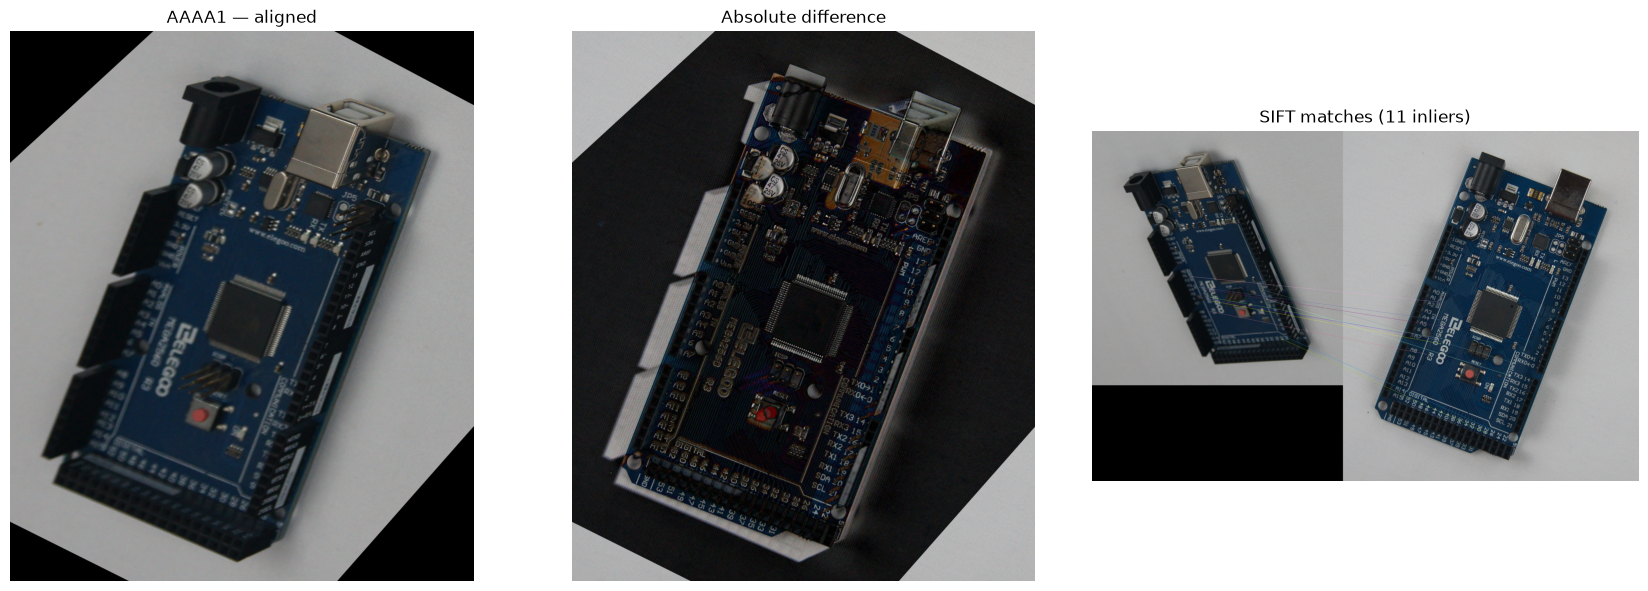


Processing ADAD1.jpg
Good matches: 281; RANSAC inliers: 170; inlier ratio: 0.605; mean abs difference: 33.406


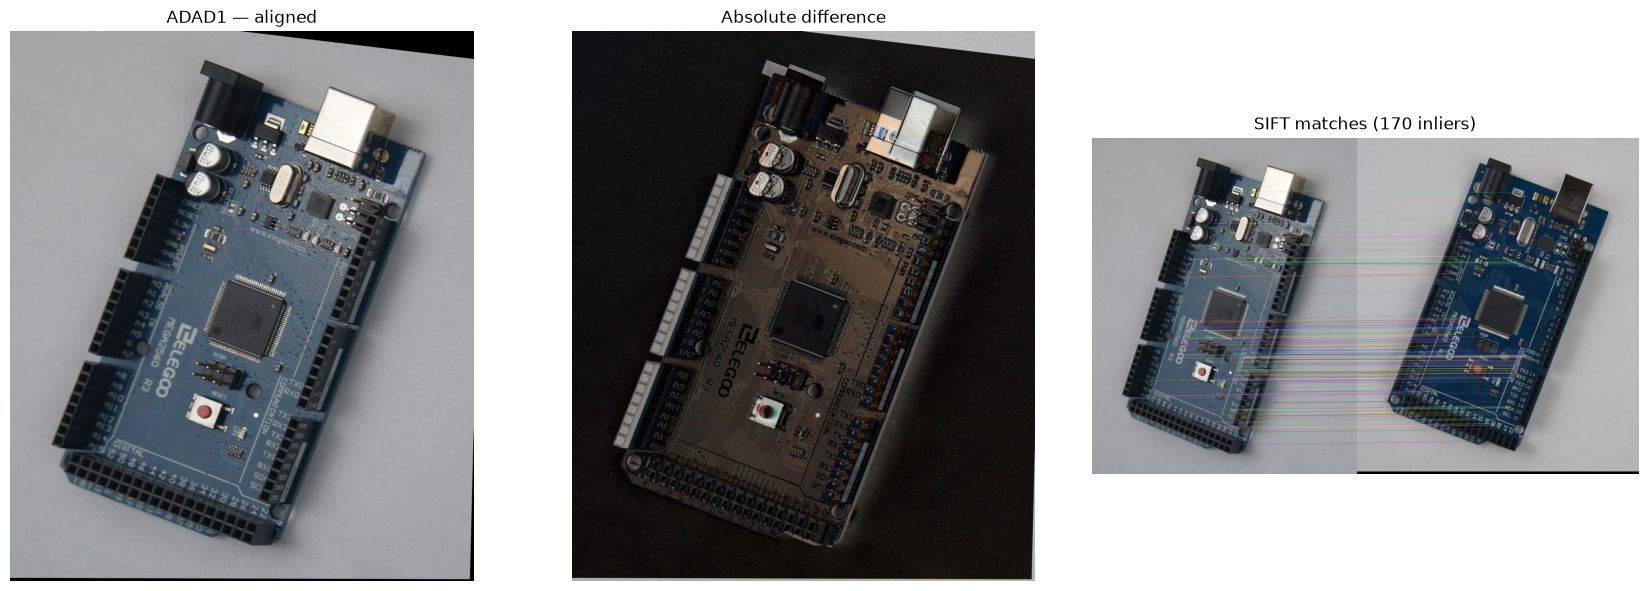


Processing AECC2.jpg
Good matches: 4059; RANSAC inliers: 3706; inlier ratio: 0.913; mean abs difference: 6.233


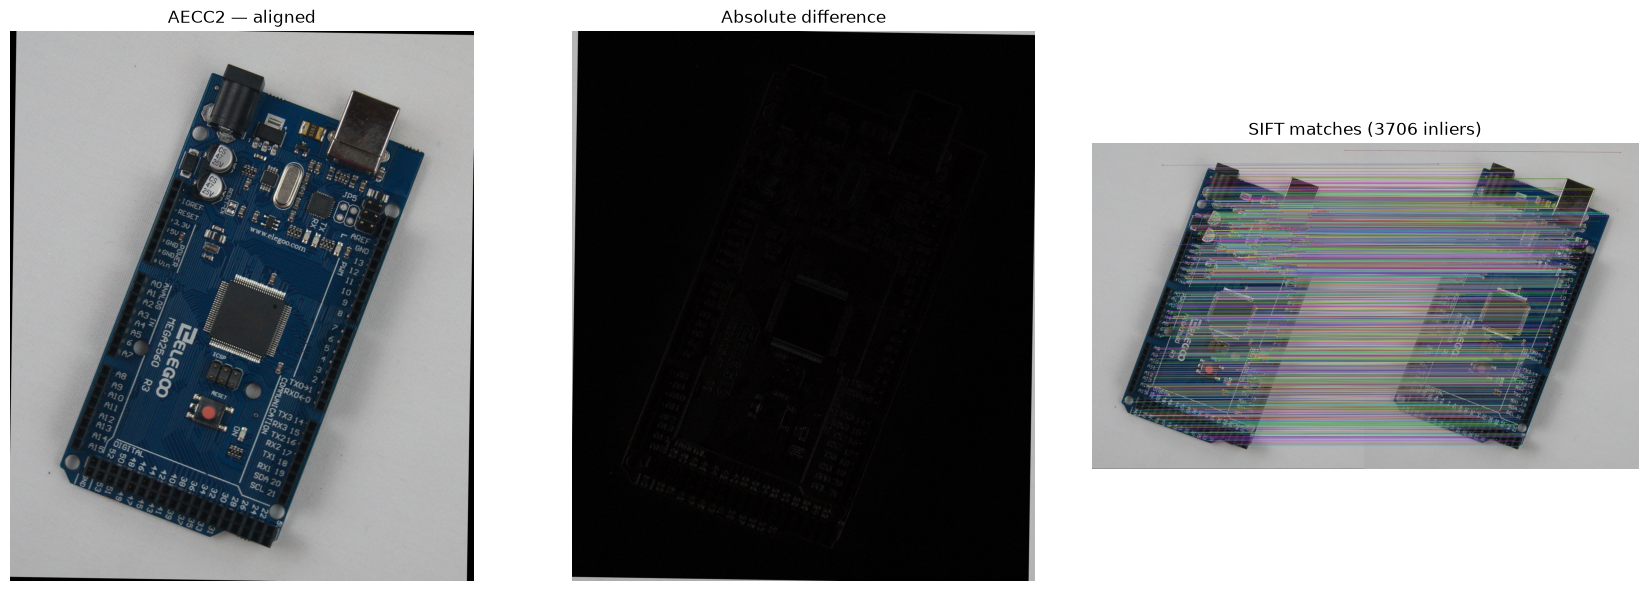


Processing AECC3.jpg
Good matches: 5265; RANSAC inliers: 4815; inlier ratio: 0.915; mean abs difference: 5.112


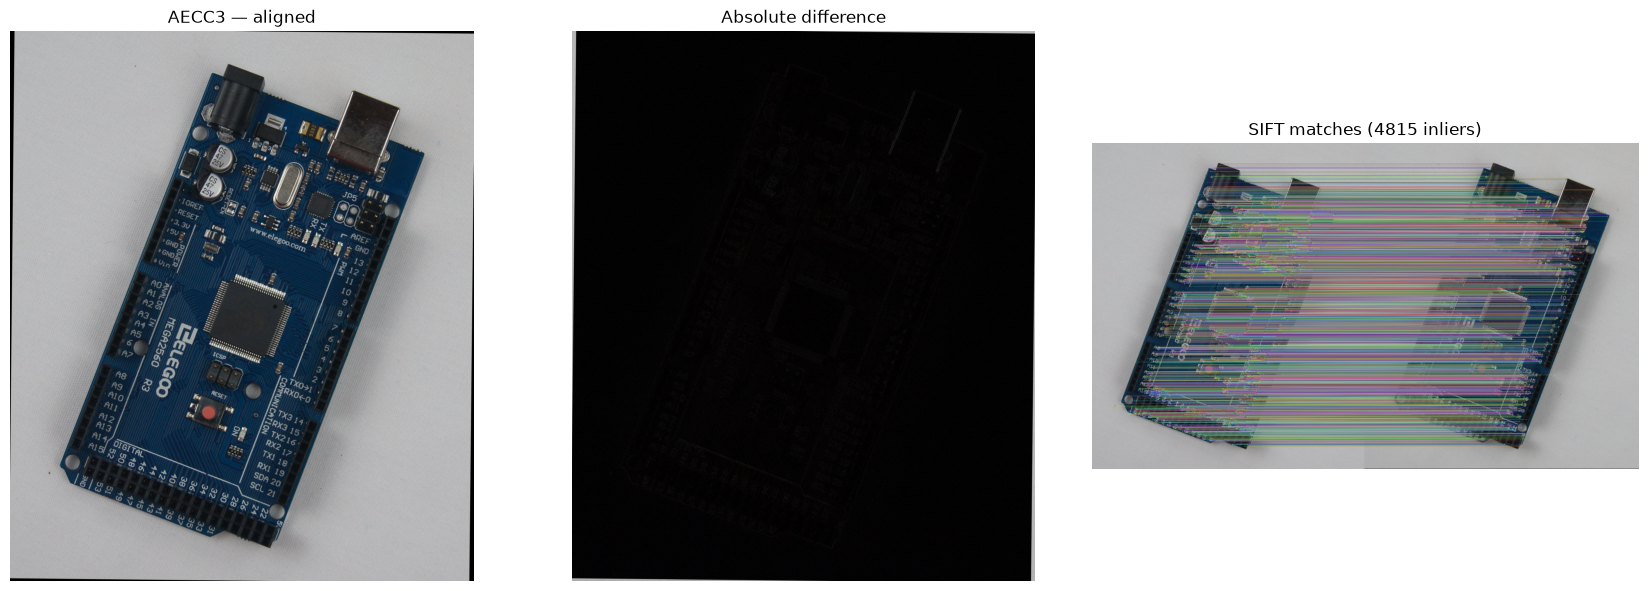


Processing AECC4.jpg
Good matches: 3558; RANSAC inliers: 3251; inlier ratio: 0.914; mean abs difference: 6.594


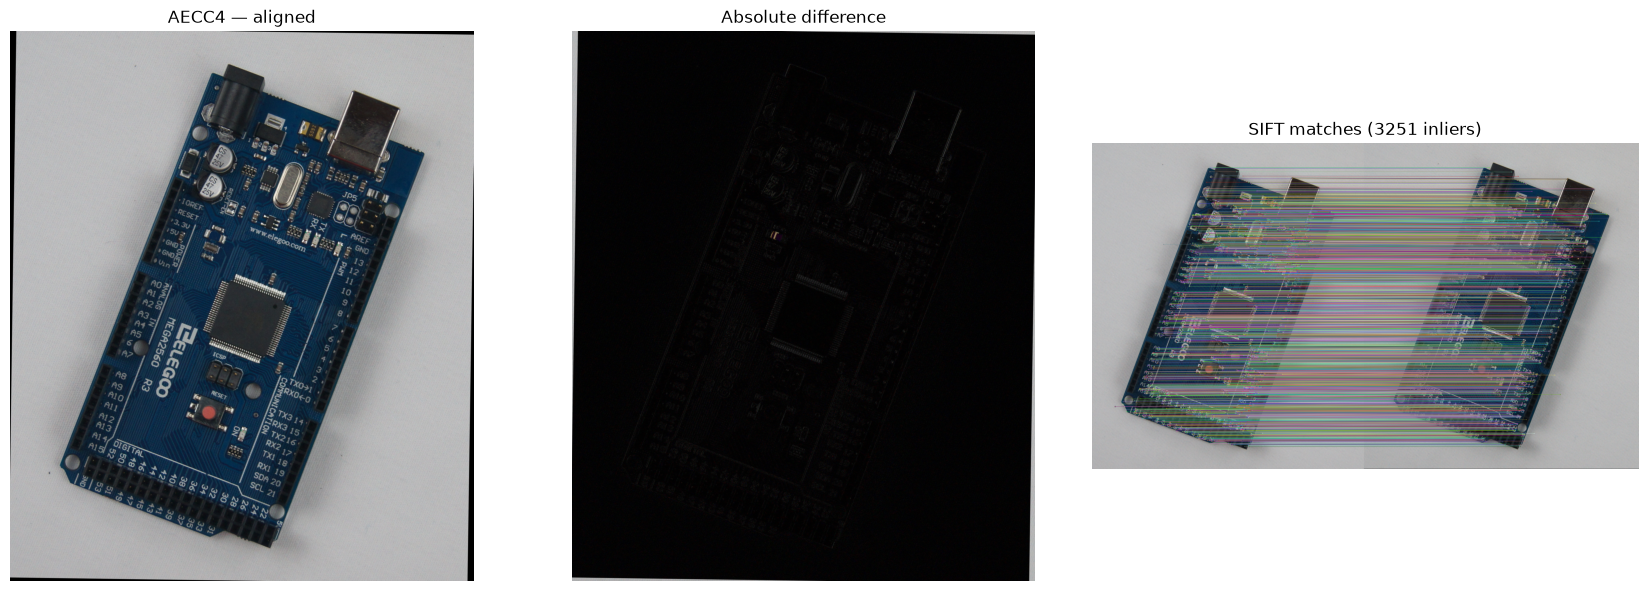

,image,good_matches,ransac_inliers,inlier_ratio,mean_absolute_difference
0,AAAA1.jpg,34,11,0.323529,46.225427
1,ADAD1.jpg,281,170,0.604982,33.405687
2,AECC2.jpg,4059,3706,0.913033,6.232813
3,AECC3.jpg,5265,4815,0.914530,5.112369
4,AECC4.jpg,3558,3251,0.913716,6.594302


Results saved in: d:\Image processing and Computer Vision\outputs\q4_pcb


In [6]:
summary = []
for path in source_paths:
    source = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if source is None:
        print("Skipping unreadable file:", path)
        continue
    print("\nProcessing", path.name)
    try:
        aligned, difference, matches_vis, H, n_good, n_inliers = align_to_template(
            template, source
        )
    except RuntimeError as exc:
        print("Skipped:", exc)
        continue

    stem = path.stem
    cv2.imwrite(str(OUT_DIR / f"{stem}_aligned.png"), aligned)
    cv2.imwrite(str(OUT_DIR / f"{stem}_difference.png"), difference)
    cv2.imwrite(str(OUT_DIR / f"{stem}_matches.png"), matches_vis)

    inlier_ratio = n_inliers / max(n_good, 1)
    mean_abs_diff = float(difference.mean())
    summary.append({
        "image": path.name,
        "good_matches": n_good,
        "ransac_inliers": n_inliers,
        "inlier_ratio": inlier_ratio,
        "mean_absolute_difference": mean_abs_diff
    })
    print(f"Good matches: {n_good}; RANSAC inliers: {n_inliers}; "
          f"inlier ratio: {inlier_ratio:.3f}; mean abs difference: {mean_abs_diff:.3f}")

    fig, axes = plt.subplots(1, 3, figsize=(17, 6))
    axes[0].imshow(cv2.cvtColor(aligned, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"{stem} — aligned")
    axes[1].imshow(cv2.cvtColor(difference, cv2.COLOR_BGR2RGB))
    axes[1].set_title("Absolute difference")
    axes[2].imshow(cv2.cvtColor(matches_vis, cv2.COLOR_BGR2RGB))
    axes[2].set_title(f"SIFT matches ({n_inliers} inliers)")
    for ax in axes:
        ax.axis("off")
    fig.tight_layout()
    plt.show()

summary_df = pd.DataFrame(summary)
display(summary_df)
summary_df.to_csv(OUT_DIR / "q4_summary.csv", index=False)
print("Results saved in:", OUT_DIR)


## Question 4(e): Why can the USB Type-B port, capacitors, and reset button show high differences?

These parts can produce large pixel differences because small alignment errors shift their sharp edges; their height or protrusion can create parallax that a single planar homography cannot correct; and illumination, reflections, shadows, focus, or exposure can change between images. A difference image therefore indicates image disagreement, not automatically a manufacturing defect. The aligned image and match inliers should be inspected before interpreting a highlighted component.